In [83]:
%config InlineBackend.figure_format = "retina"

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    font_scale=0.9,
    rc={
        # Figure size and quality
        "figure.figsize": (17, 7),
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "figure.facecolor": "#FFFFFF",
        "axes.facecolor": "#FFFFFF",

        # Text and typography
        "text.color": "#222222",
        "axes.labelcolor": "#444444",
        "axes.titlecolor": "#222222",
        "xtick.color": "#555555",
        "ytick.color": "#555555",
        "axes.titlesize": 14,
        "axes.titleweight": "semibold",
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,

        # Square grid (horizontal + vertical)
        "axes.grid": True,
        "axes.grid.axis": "both",
        "axes.axisbelow": True,
        "grid.color": "#DDE2E8",
        "grid.alpha": 0.7,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",

        # Lines and markers
        "lines.linewidth": 2,
        "lines.markersize": 5,

        # Clean borders
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#DDE2E8",
        "legend.frameon": False,

        # Spacing
        "axes.titlepad": 12,
        "axes.labelpad": 8,
    }
)

In [84]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df.job_posted_date)
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [85]:
df_DA = df[df['job_title_short'] == 'Data Analyst'].copy()

In [86]:
df_DA['job_posted_month_no'] = df_DA['job_posted_date'].dt.month

In [87]:
df_DA_explode = df_DA.explode('job_skills')

In [88]:
df_DA_pivot = df_DA_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)

In [89]:
df_DA_pivot.loc['Total'] = df_DA_pivot.sum()

In [90]:
df_DA_pivot = df_DA_pivot[df_DA_pivot.loc['Total'].sort_values(ascending=False).index]

In [91]:
df_DA_pivot = df_DA_pivot.drop(index='Total')

In [92]:
df_DA_pivot

job_skills,sql,excel,python,tableau,power bi,r,sas,powerpoint,word,sap,...,xamarin,mattermost,gtx,esquisse,chainer,capacitor,nuxt.js,msaccess,ovh,suse
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,11336,8170,6606,5596,4285,3607,3830,1880,1778,1251,...,0,0,0,0,0,1,1,0,0,0
2,7947,5772,4751,3936,3307,2576,2634,1291,1235,954,...,0,0,0,0,0,0,0,0,0,0
3,7868,5675,4741,4051,3176,2650,2554,1266,1203,892,...,1,0,0,0,0,0,0,0,0,1
4,7553,5496,4557,3776,3106,2399,2598,1190,1177,947,...,0,0,0,0,0,0,0,0,1,0
5,6617,4773,4070,3245,2695,2093,1940,979,957,851,...,0,0,0,0,0,0,0,1,0,0
6,7584,5724,4707,3812,3275,2442,2174,1173,1237,987,...,0,0,0,0,0,0,0,0,0,0
7,7687,5513,4831,3928,3350,2444,2118,1096,1069,996,...,0,0,1,0,0,0,0,0,0,0
8,8823,6482,5576,4533,3859,2975,2560,1332,1298,1117,...,0,0,0,0,0,0,0,0,0,0
9,6829,4886,4229,3446,3118,2146,1880,944,945,852,...,0,1,0,0,0,0,0,0,0,0


In [93]:
df_DA_pivot = df_DA_pivot.reset_index()
df_DA_pivot['job_posted_month'] = df_DA_pivot['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%B'))
df_DA_pivot = df_DA_pivot.set_index('job_posted_month')
df_DA_pivot = df_DA_pivot.drop(columns='job_posted_month_no')


<Axes: title={'center': 'Top 10 Skills For Data Analysis Job'}, xlabel='Months', ylabel='Posted Jobs'>

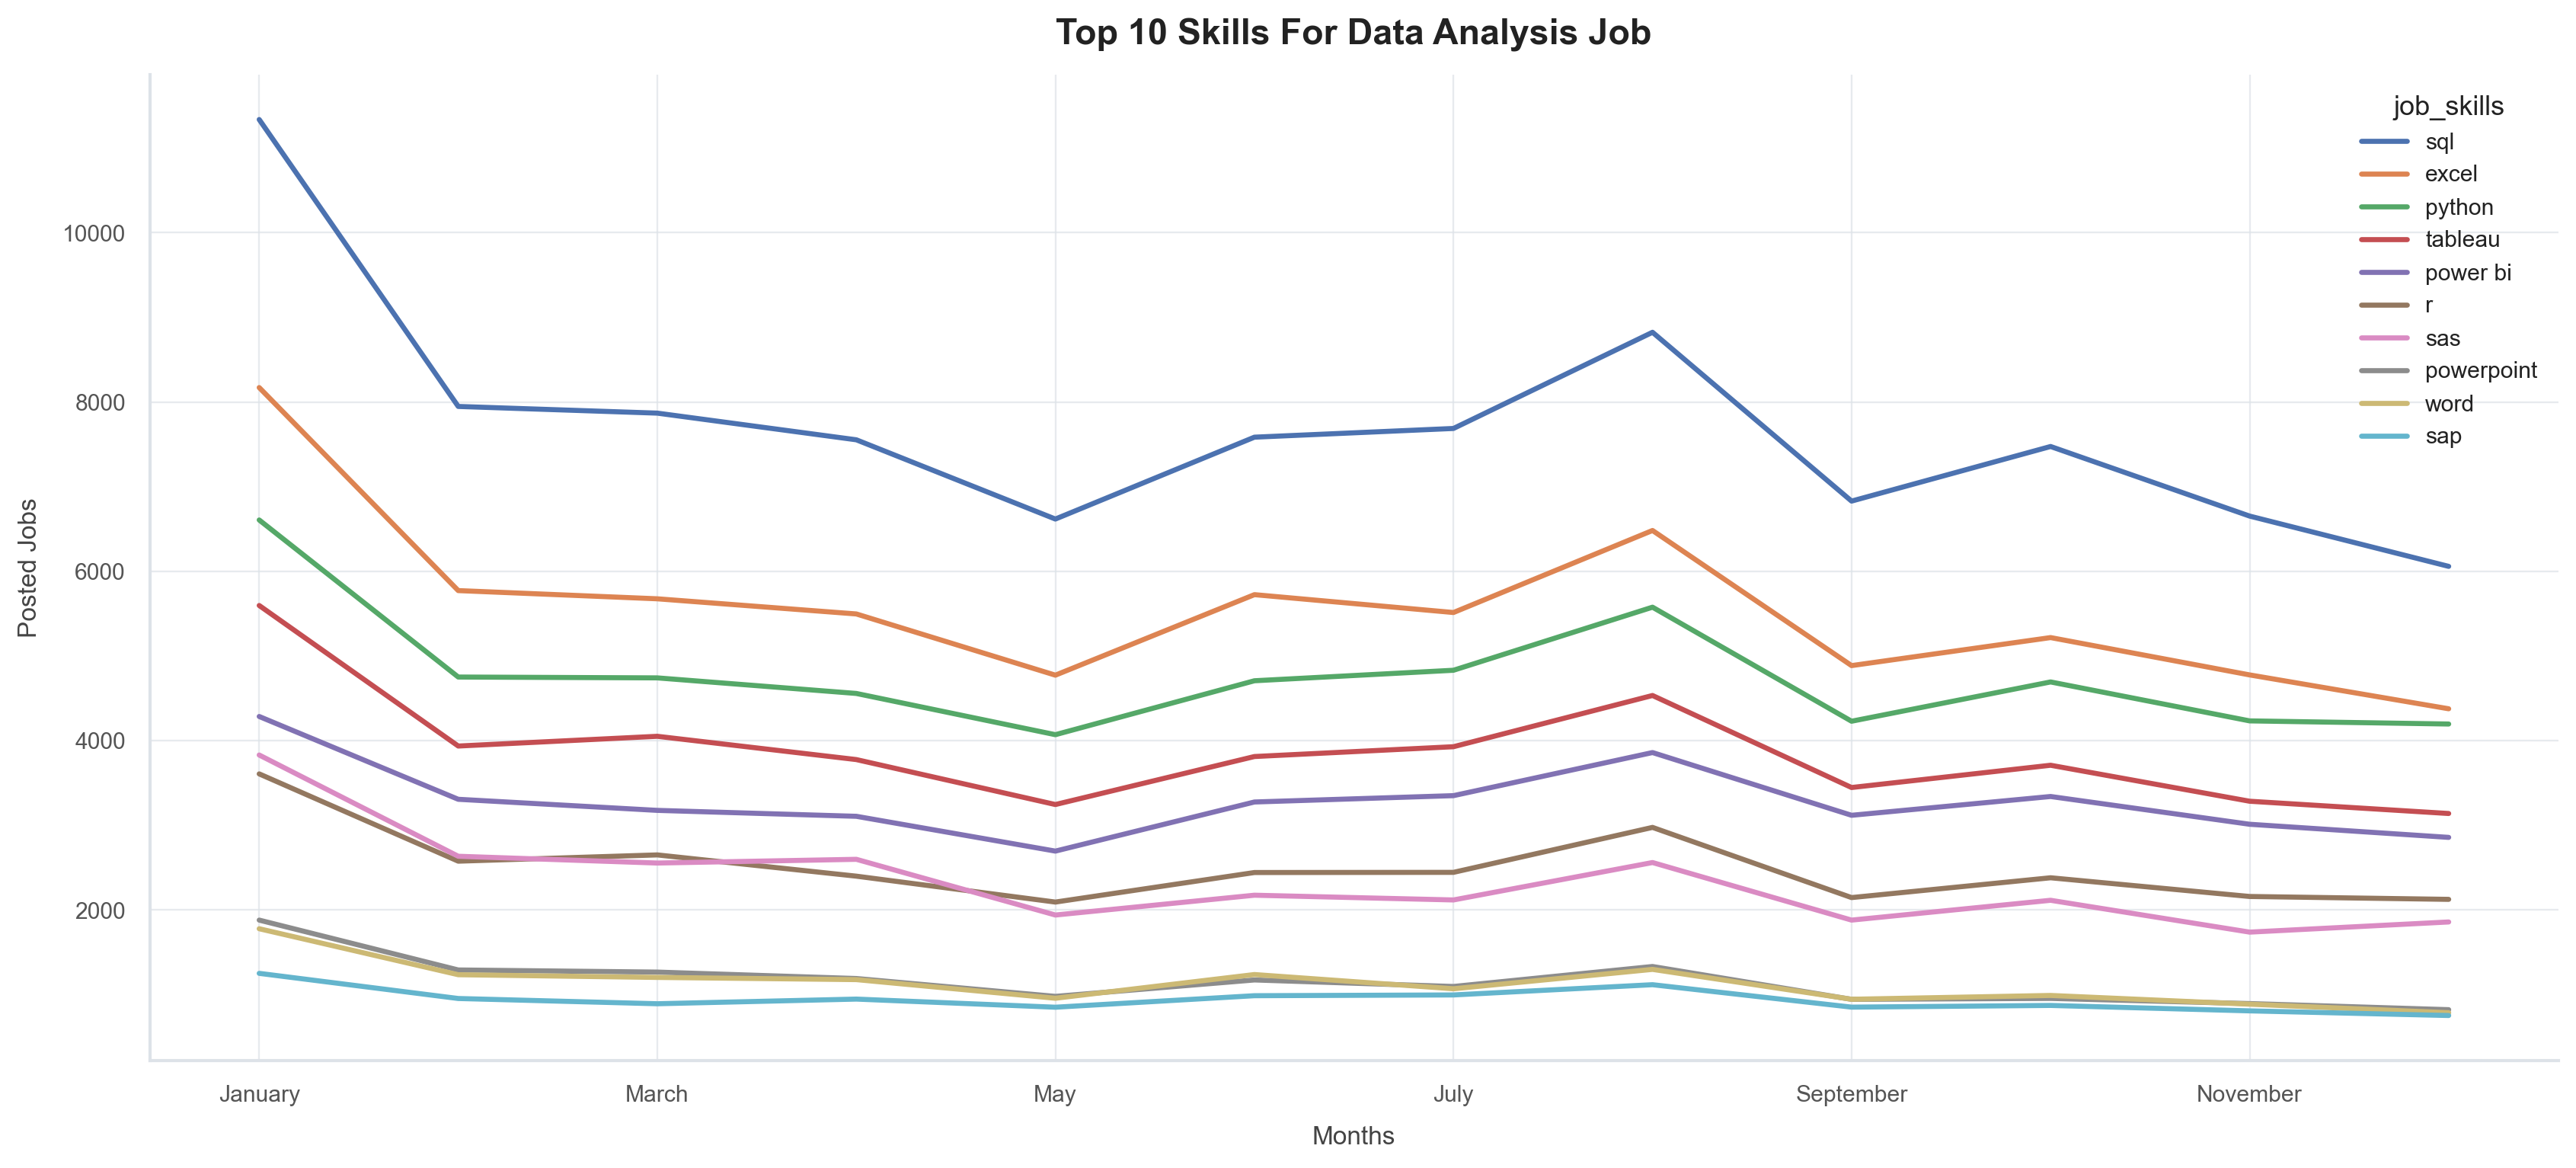

In [94]:
df_DA_pivot.iloc[:,:10].plot(kind='line', figsize=(17,7), title='Top 10 Skills For Data Analysis Job', xlabel='Months', ylabel='Posted Jobs')